In [1]:
!pip -q install pandas numpy matplotlib seaborn scipy statsmodels

In [2]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

uploaded = files.upload()

Saving imdweb_lVBwxWGL.nc to imdweb_lVBwxWGL (1).nc


In [7]:
import xarray as xr

filename = next(iter(uploaded))

# Open the specific group 'tmax' in the NetCDF dataset
ds = xr.open_dataset(filename, group='tmax')

# Inspect the loaded dataset group
print("Dataset structure for 'tmax' group:")
print(ds)

# Display coordinate and variable information
print("\nTime coordinate sample:")
print(ds['time'].values[:5])

Dataset structure for 'tmax' group:
<xarray.Dataset> Size: 532kB
Dimensions:      (time: 9497, lat: 3, lon: 2)
Coordinates:
  * time         (time) datetime64[ns] 76kB 2000-01-01 2000-01-02 ... 2025-12-31
  * lat          (lat) float64 24B 30.5 31.5 32.5
  * lon          (lon) float64 16B 75.5 76.5
Data variables:
    tmax         (time, lat, lon) float64 456kB ...
    spatial_ref  int64 8B ...
Attributes:
    Conventions:  CF-1.7
    title:        IMD gridded data
    source:       https://imdpune.gov.in/
    history:      2026-10-14 18:56:39.539776 Python
    references:   
    comment:      

Time coordinate sample:
['2000-01-01T00:00:00.000000000' '2000-01-02T00:00:00.000000000'
 '2000-01-03T00:00:00.000000000' '2000-01-04T00:00:00.000000000'
 '2000-01-05T00:00:00.000000000']


In [9]:
# Convert the xarray dataset to a pandas DataFrame
df = ds.to_dataframe().reset_index()

# Save the inspected sample
df.to_csv("temperature_sample_inspected.csv", index=False)

# Record the schema
schema = pd.DataFrame({
    "column": df.columns,
    "data_type": df.dtypes.astype(str).values,
    "missing_values": df.isna().sum().values
})

display(schema)

schema.to_csv("temperature_sample_schema.csv", index=False)

,column,data_type,missing_values
0,time,datetime64[ns],0
1,lat,float64,0
2,lon,float64,0
3,tmax,float64,9497
4,spatial_ref,int64,0


In [10]:
print(ds)

<xarray.Dataset> Size: 532kB
Dimensions:      (time: 9497, lat: 3, lon: 2)
Coordinates:
  * time         (time) datetime64[ns] 76kB 2000-01-01 2000-01-02 ... 2025-12-31
  * lat          (lat) float64 24B 30.5 31.5 32.5
  * lon          (lon) float64 16B 75.5 76.5
Data variables:
    tmax         (time, lat, lon) float64 456kB 17.64 16.66 19.11 ... 11.44 nan
    spatial_ref  int64 8B 0
Attributes:
    Conventions:  CF-1.7
    title:        IMD gridded data
    source:       https://imdpune.gov.in/
    history:      2026-10-14 18:56:39.539776 Python
    references:   
    comment:      


In [11]:
tmax = ds["tmax"]

print("Dataset dimensions:")
print(tmax.dims)

print("\nDate range:")
print("Start:", str(ds["time"].min().values)[:10])
print("End:", str(ds["time"].max().values)[:10])

print("\nNumber of daily records:")
print(ds.sizes["time"])

print("\nMissing observations by grid cell:")
display(tmax.isnull().sum(dim="time").to_dataframe())

Dataset dimensions:
('time', 'lat', 'lon')

Date range:
Start: 2000-01-01
End: 2025-12-31

Number of daily records:
9497

Missing observations by grid cell:


tmax
lat  lon       
30.5 75.5     0
     76.5     0
31.5 75.5     0
     76.5     0
32.5 75.5     0
     76.5  9497

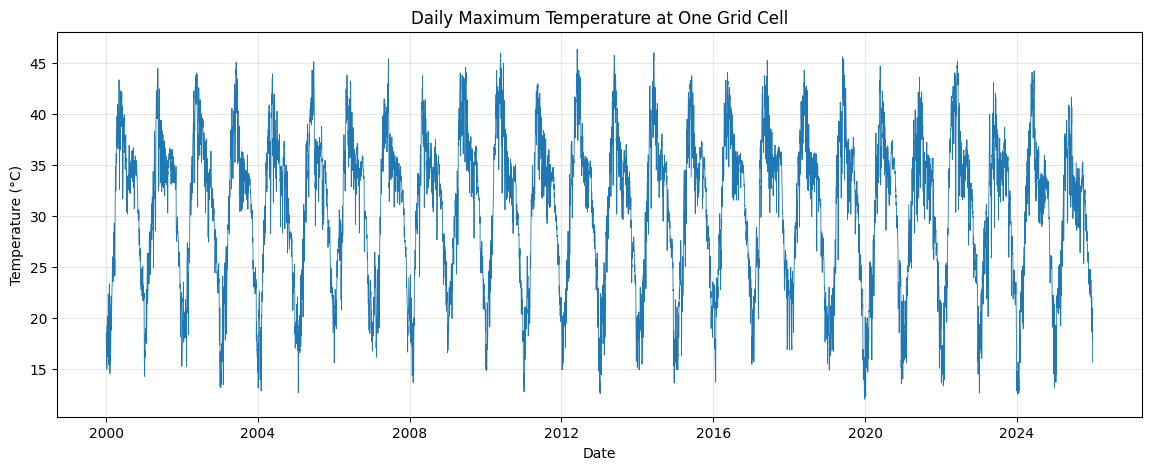

In [12]:
series = tmax.isel(lat=0, lon=0).to_series()

plt.figure(figsize=(14, 5))
plt.plot(series.index, series.values, linewidth=0.6)

plt.title("Daily Maximum Temperature at One Grid Cell")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.grid(alpha=0.3)
plt.show()

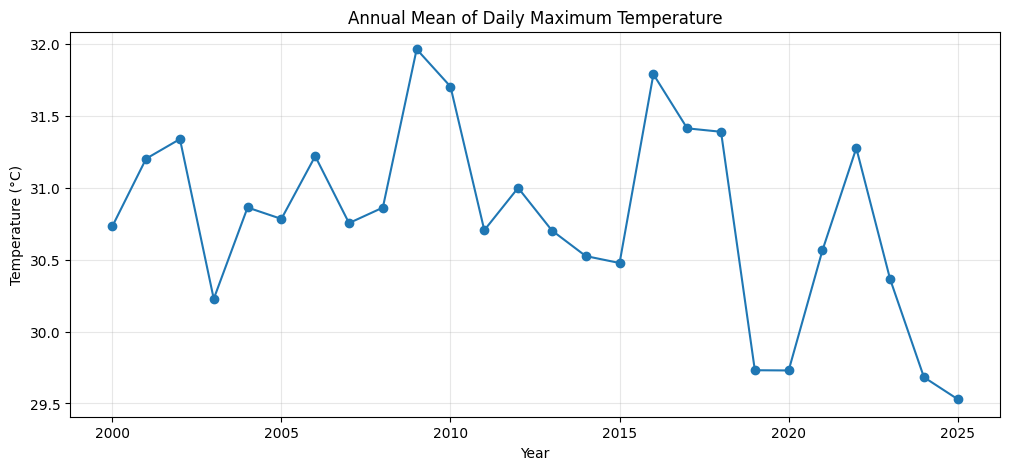

,annual_mean_tmax
time,
2000,30.732241
2001,31.203562
2002,31.340082
2003,30.227671
2004,30.863770
2005,30.784301
2006,31.220931
2007,30.755233
2008,30.863060


In [13]:
annual_mean = series.groupby(series.index.year).mean()

plt.figure(figsize=(12, 5))
plt.plot(annual_mean.index, annual_mean.values, marker="o")

plt.title("Annual Mean of Daily Maximum Temperature")
plt.xlabel("Year")
plt.ylabel("Temperature (°C)")
plt.grid(alpha=0.3)
plt.show()

display(annual_mean.to_frame("annual_mean_tmax"))

In [14]:
print("DATASET SUMMARY")
print(ds)

print("\nDATAFRAME SHAPE")
print(df.shape)

print("\nDATAFRAME COLUMNS")
print(df.columns.tolist())

print("\nFIRST 10 ROWS")
display(df.head(10))

print("\nDATA TYPES")
print(df.dtypes)

print("\nTEMPERATURE SUMMARY")
display(ds["tmax"].to_dataframe().describe())

print("\nMISSING VALUES IN DATAFRAME")
display(df.isna().sum().to_frame("missing_values"))

DATASET SUMMARY
<xarray.Dataset> Size: 532kB
Dimensions:      (time: 9497, lat: 3, lon: 2)
Coordinates:
  * time         (time) datetime64[ns] 76kB 2000-01-01 2000-01-02 ... 2025-12-31
  * lat          (lat) float64 24B 30.5 31.5 32.5
  * lon          (lon) float64 16B 75.5 76.5
Data variables:
    tmax         (time, lat, lon) float64 456kB 17.64 16.66 19.11 ... 11.44 nan
    spatial_ref  int64 8B 0
Attributes:
    Conventions:  CF-1.7
    title:        IMD gridded data
    source:       https://imdpune.gov.in/
    history:      2026-10-14 18:56:39.539776 Python
    references:   
    comment:      

DATAFRAME SHAPE
(56982, 5)

DATAFRAME COLUMNS
['time', 'lat', 'lon', 'tmax', 'spatial_ref']

FIRST 10 ROWS


,time,lat,lon,tmax,spatial_ref
0,2000-01-01,30.5,75.5,17.639999,0
1,2000-01-01,30.5,76.5,16.660000,0
2,2000-01-01,31.5,75.5,19.110001,0
3,2000-01-01,31.5,76.5,17.320000,0
4,2000-01-01,32.5,75.5,17.980000,0
5,2000-01-01,32.5,76.5,NaN,0
6,2000-01-02,30.5,75.5,18.610001,0
7,2000-01-02,30.5,76.5,18.340000,0
8,2000-01-02,31.5,75.5,19.780001,0
9,2000-01-02,31.5,76.5,18.020000,0



DATA TYPES
time           datetime64[ns]
lat                   float64
lon                   float64
tmax                  float64
spatial_ref             int64
dtype: object

TEMPERATURE SUMMARY


,tmax
count,47485.000000
mean,28.546923
std,7.014213
min,7.429101
25%,23.129999
50%,30.010000
75%,33.650002
max,46.310001



MISSING VALUES IN DATAFRAME


,missing_values
time,0
lat,0
lon,0
tmax,9497
spatial_ref,0


In [15]:
# Count valid and missing observations at each grid cell
valid_days = ds["tmax"].count(dim="time")
missing_days = ds["tmax"].isnull().sum(dim="time")
missing_percent = (missing_days / ds.sizes["time"]) * 100

quality_check = xr.Dataset({
    "valid_days": valid_days,
    "missing_days": missing_days,
    "missing_percent": missing_percent
})

display(quality_check.to_dataframe())

valid_days  missing_days  missing_percent
lat  lon                                            
30.5 75.5        9497             0              0.0
     76.5        9497             0              0.0
31.5 75.5        9497             0              0.0
     76.5        9497             0              0.0
32.5 75.5        9497             0              0.0
     76.5           0          9497            100.0

In [16]:
print("Temperature units:", ds["tmax"].attrs.get("units", "Not specified"))
print("Temperature long name:", ds["tmax"].attrs.get("long_name", "Not specified"))

dates = pd.DatetimeIndex(ds["time"].values)

print("\nDuplicate dates:", dates.duplicated().sum())
print("Date gaps:", len(pd.date_range(
    dates.min(), dates.max(), freq="D"
).difference(dates)))
print("First date:", dates.min())
print("Last date:", dates.max())

Temperature units: C
Temperature long name: Maximum Temperature

Duplicate dates: 0
Date gaps: 0
First date: 2000-01-01 00:00:00
Last date: 2025-12-31 00:00:00


In [17]:
quality_check = pd.DataFrame({
    "valid_days": ds["tmax"].count(dim="time").values.flatten(),
    "missing_days": ds["tmax"].isnull().sum(dim="time").values.flatten(),
    "missing_percent": (
        ds["tmax"].isnull().mean(dim="time").values.flatten() * 100
    ),
}, index=pd.MultiIndex.from_product(
    [ds["lat"].values, ds["lon"].values],
    names=["latitude", "longitude"]
))

display(quality_check.round(2))

valid_days  missing_days  missing_percent
latitude longitude                                           
30.5     75.5             9497             0              0.0
         76.5             9497             0              0.0
31.5     75.5             9497             0              0.0
         76.5             9497             0              0.0
32.5     75.5             9497             0              0.0
         76.5                0          9497            100.0

In [18]:
print("Temperature units:", ds["tmax"].attrs.get("units", "Not specified"))
print("Temperature long name:", ds["tmax"].attrs.get("long_name", "Not specified"))

dates = pd.DatetimeIndex(ds["time"].values)

print("\nDuplicate dates:", dates.duplicated().sum())
print("Date gaps:", len(pd.date_range(
    dates.min(), dates.max(), freq="D"
).difference(dates)))
print("First date:", dates.min())
print("Last date:", dates.max())

Temperature units: C
Temperature long name: Maximum Temperature

Duplicate dates: 0
Date gaps: 0
First date: 2000-01-01 00:00:00
Last date: 2025-12-31 00:00:00


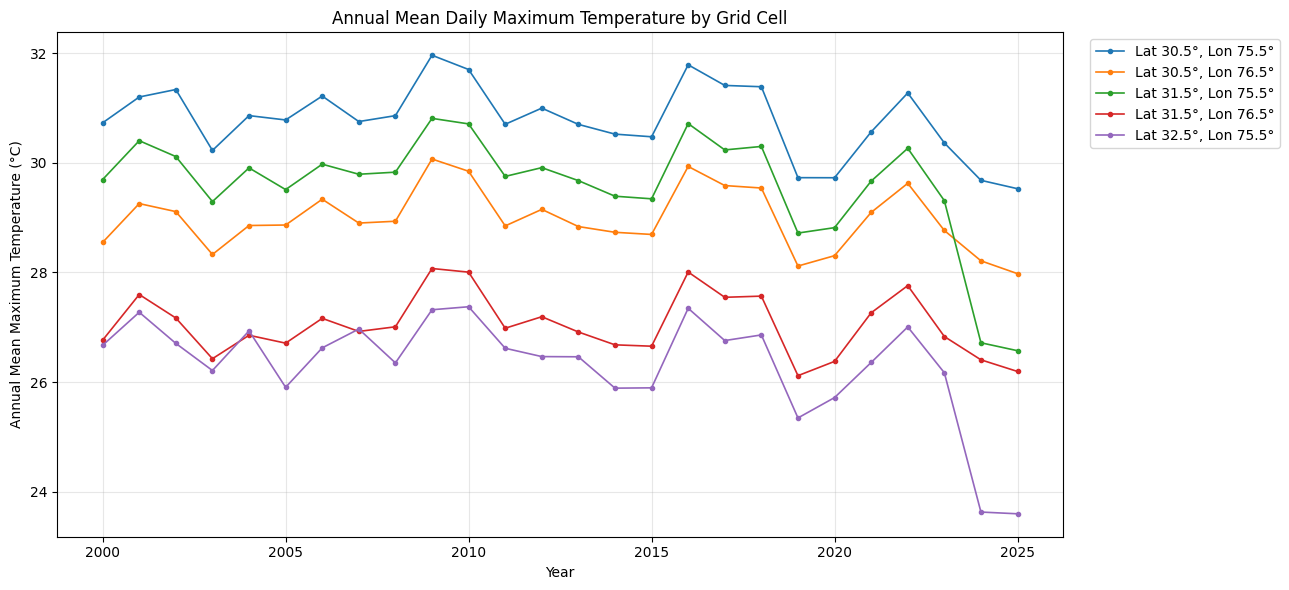

In [19]:
# Calculate annual mean maximum temperature for every grid cell
annual_grid = ds["tmax"].groupby("time.year").mean(dim="time")

# Plot the annual series for each grid cell
plt.figure(figsize=(13, 6))

for lat in ds["lat"].values:
    for lon in ds["lon"].values:
        series = annual_grid.sel(lat=lat, lon=lon)

        # Skip locations with no valid temperature data
        if np.isfinite(series.values).any():
            plt.plot(
                annual_grid["year"].values,
                series.values,
                marker="o",
                markersize=3,
                linewidth=1.2,
                label=f"Lat {lat}°, Lon {lon}°"
            )

plt.title("Annual Mean Daily Maximum Temperature by Grid Cell")
plt.xlabel("Year")
plt.ylabel("Annual Mean Maximum Temperature (°C)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
annual_table = annual_grid.to_dataframe(name="annual_mean_tmax").reset_index()

annual_table = annual_table.dropna(subset=["annual_mean_tmax"])

display(annual_table.round(2))

,year,lat,lon,annual_mean_tmax
0,2000,30.5,75.5,30.73
1,2000,30.5,76.5,28.55
2,2000,31.5,75.5,29.70
3,2000,31.5,76.5,26.76
4,2000,32.5,75.5,26.67
...,...,...,...,...
150,2025,30.5,75.5,29.53
151,2025,30.5,76.5,27.98
152,2025,31.5,75.5,26.57
153,2025,31.5,76.5,26.19


In [21]:
quality_check = quality_check.reset_index()

display(
    quality_check[
        [
            "latitude",
            "longitude",
            "valid_days",
            "missing_days",
            "missing_percent"
        ]
    ].round(2)
)

,latitude,longitude,valid_days,missing_days,missing_percent
0,30.5,75.5,9497,0,0.0
1,30.5,76.5,9497,0,0.0
2,31.5,75.5,9497,0,0.0
3,31.5,76.5,9497,0,0.0
4,32.5,75.5,9497,0,0.0
5,32.5,76.5,0,9497,100.0


In [22]:
annual_table.to_csv("annual_mean_temperature_by_grid_cell.csv", index=False)

print("Saved annual temperature summary.")

Saved annual temperature summary.


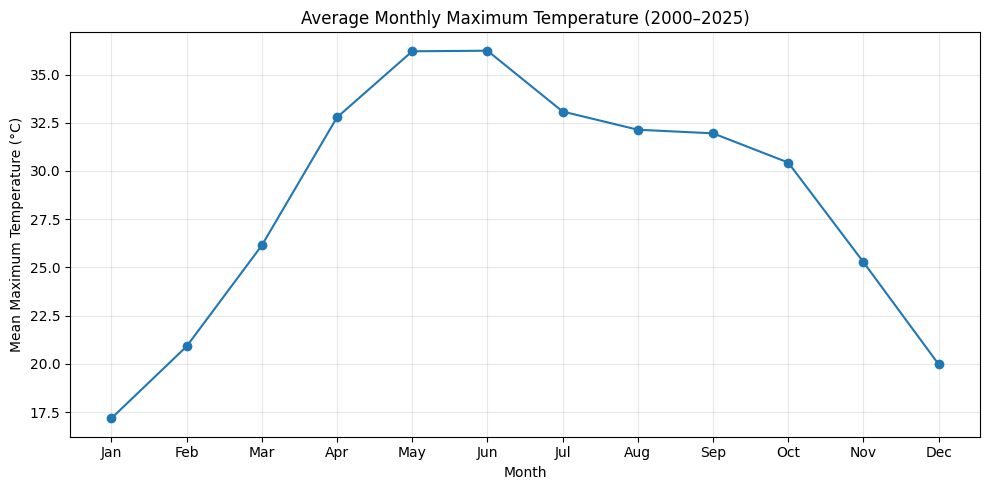

,monthly_mean_tmax
month,
1,17.17
2,20.90
3,26.14
4,32.78
5,36.20
6,36.23
7,33.08
8,32.14
9,31.95


In [23]:
# Average maximum temperature for each calendar month
monthly_mean = ds["tmax"].groupby("time.month").mean(
    dim=["time", "lat", "lon"]
)

plt.figure(figsize=(10, 5))
plt.plot(
    monthly_mean["month"].values,
    monthly_mean.values,
    marker="o"
)

plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.title("Average Monthly Maximum Temperature (2000–2025)")
plt.xlabel("Month")
plt.ylabel("Mean Maximum Temperature (°C)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(monthly_mean.to_dataframe(name="monthly_mean_tmax").round(2))

In [24]:

# Calculate the 90th-percentile temperature threshold
# separately for each grid cell and calendar month.

monthly_threshold = ds["tmax"].groupby("time.month").quantile(
    0.90,
    dim="time",
    skipna=True
)

print("Monthly threshold dataset:")
print(monthly_threshold)

display(
    monthly_threshold.to_dataframe(name="threshold_90th_percentile")
    .dropna()
    .round(2)
)

Monthly threshold dataset:
<xarray.DataArray 'tmax' (month: 12, lat: 3, lon: 2)> Size: 576B
array([[[22.13500023, 21.26500034],
        [21.58500004, 19.46102715],
        [18.29235268,         nan]],

       [[27.06417542, 25.86000061],
        [26.06199951, 23.453405  ],
        [22.48983345,         nan]],

       [[33.36304474, 32.02001953],
        [32.15166664, 29.58747864],
        [28.56499958,         nan]],

       [[40.30153236, 38.03169861],
        [38.51932068, 35.27176018],
        [33.94302635,         nan]],

       [[42.90732193, 40.44048882],
        [41.65044785, 37.79500008],
        [37.00828743,         nan]],

...

       [[36.26000023, 33.84499931],
        [35.09000015, 32.39423752],
        [32.84094238,         nan]],

       [[36.32224617, 33.91005821],
        [35.17738113, 32.2776165 ],
        [32.5721611 ,         nan]],

       [[35.29633713, 32.99589157],
        [34.09565735, 31.30254364],
        [31.22626686,         nan]],

       [[30.01929283, 2

/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1650: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1650: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1650: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1650: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1650: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1650: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1650: RuntimeWarning: All-NaN slice encountered
  return f

quantile  threshold_90th_percentile
month lat  lon                                      
1     30.5 75.5       0.9                      22.14
           76.5       0.9                      21.27
      31.5 75.5       0.9                      21.59
           76.5       0.9                      19.46
      32.5 75.5       0.9                      18.29
2     30.5 75.5       0.9                      27.06
           76.5       0.9                      25.86
      31.5 75.5       0.9                      26.06
           76.5       0.9                      23.45
      32.5 75.5       0.9                      22.49
3     30.5 75.5       0.9                      33.36
           76.5       0.9                      32.02
      31.5 75.5       0.9                      32.15
           76.5       0.9                      29.59
      32.5 75.5       0.9                      28.56
4     30.5 75.5       0.9                      40.30
           76.5       0.9                      38.03
      31.5 75.5       0.9                      38.52
           76.5       0.9                      35.27
      32.5 75.5       0.9                      33.94
5     30.5 75.5       0.9                      42.91
           76.5       0.9                      40.44
      31.5 75.5       0.9                      41.65
           76.5       0.9                      37.80
      32.5 75.5       0.9                      37.01
6     30.5 75.5       0.9                      43.25
           76.5       0.9                      40.44
      31.5 75.5       0.9                      41.97
           76.5       0.9                      38.18
      32.5 75.5       0.9                      37.58
7     30.5 75.5       0.9                      38.04
           76.5       0.9                      35.39
      31.5 75.5       0.9                      36.86
           76.5       0.9                      33.84
      32.5 75.5       0.9                      34.32
8     30.5 75.5       0.9                      36.26
           76.5       0.9                      33.84
      31.5 75.5       0.9                      35.09
           76.5       0.9                      32.39
      32.5 75.5       0.9                      32.84
9     30.5 75.5       0.9                      36.32
           76.5       0.9                      33.91
      31.5 75.5       0.9                      35.18
           76.5       0.9                      32.28
      32.5 75.5       0.9                      32.57
10    30.5 75.5       0.9                      35.30
           76.5       0.9                      33.00
      31.5 75.5       0.9                      34.10
           76.5       0.9                      31.30
      32.5 75.5       0.9                      31.23
11    30.5 75.5       0.9                      30.02
           76.5       0.9                      28.23
      31.5 75.5       0.9                      29.02
           76.5       0.9                      26.44
      32.5 75.5       0.9                      26.09
12    30.5 75.5       0.9                      25.08
           76.5       0.9                      23.93
      31.5 75.5       0.9                      24.26
           76.5       0.9                      22.05
      32.5 75.5       0.9                      21.19

In [25]:

# Match each daily temperature to its grid-cell/month threshold.
daily_threshold = monthly_threshold.sel(month=ds["time"].dt.month)

# Mark a day as extreme when it exceeds the relevant threshold.
extreme_day = ds["tmax"] > daily_threshold

# Count extreme days per year at each grid cell.
annual_extreme_days = extreme_day.groupby("time.year").sum(dim="time")

# Keep locations with at least some valid data.
annual_extreme_table = (
    annual_extreme_days
    .to_dataframe(name="extreme_heat_days")
    .reset_index()
    .dropna(subset=["extreme_heat_days"])
)

display(annual_extreme_table.head(15))

,year,lat,lon,quantile,extreme_heat_days
0,2000,30.5,75.5,0.9,26
1,2000,30.5,76.5,0.9,10
2,2000,31.5,75.5,0.9,23
3,2000,31.5,76.5,0.9,12
4,2000,32.5,75.5,0.9,37
5,2000,32.5,76.5,0.9,0
6,2001,30.5,75.5,0.9,42
7,2001,30.5,76.5,0.9,43
8,2001,31.5,75.5,0.9,43
9,2001,31.5,76.5,0.9,39


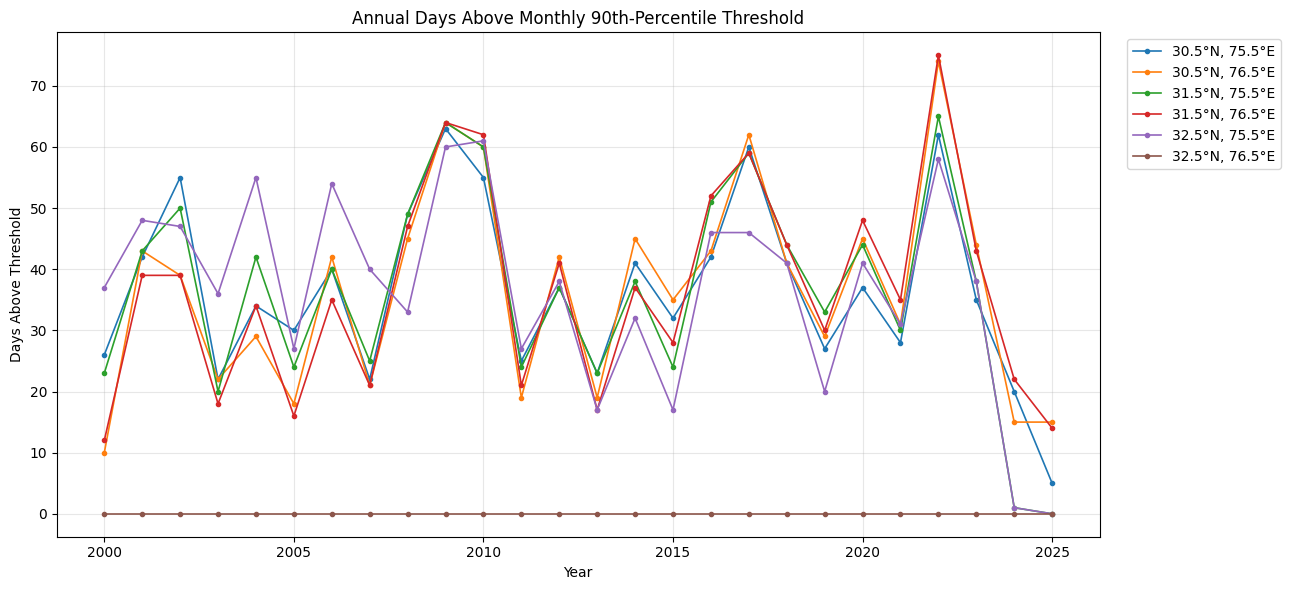

In [26]:

plt.figure(figsize=(13, 6))

for lat in ds["lat"].values:
    for lon in ds["lon"].values:
        location_data = annual_extreme_table[
            (annual_extreme_table["lat"] == lat) &
            (annual_extreme_table["lon"] == lon)
        ]

        if not location_data.empty:
            plt.plot(
                location_data["year"],
                location_data["extreme_heat_days"],
                marker="o",
                markersize=3,
                linewidth=1.2,
                label=f"{lat}°N, {lon}°E"
            )

plt.title("Annual Days Above Monthly 90th-Percentile Threshold")
plt.xlabel("Year")
plt.ylabel("Days Above Threshold")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:

# Keep missing temperature observations as missing,
# instead of counting them as non-extreme days.

valid_temperature = ds["tmax"].notnull()

daily_threshold = monthly_threshold.sel(
    month=ds["time"].dt.month
)

extreme_day = (ds["tmax"] > daily_threshold).where(valid_temperature)

annual_extreme_days = extreme_day.groupby("time.year").sum(
    dim="time",
    skipna=True
)

# Mask grid cells that have no valid observations at all.
has_data = valid_temperature.any(dim="time")
annual_extreme_days = annual_extreme_days.where(has_data)

annual_extreme_table = (
    annual_extreme_days
    .to_dataframe(name="extreme_heat_days")
    .reset_index()
    .dropna(subset=["extreme_heat_days"])
)

display(annual_extreme_table.head(15))

,year,lat,lon,quantile,extreme_heat_days
0,2000,30.5,75.5,0.9,26.0
1,2000,30.5,76.5,0.9,10.0
2,2000,31.5,75.5,0.9,23.0
3,2000,31.5,76.5,0.9,12.0
4,2000,32.5,75.5,0.9,37.0
6,2001,30.5,75.5,0.9,42.0
7,2001,30.5,76.5,0.9,43.0
8,2001,31.5,75.5,0.9,43.0
9,2001,31.5,76.5,0.9,39.0
10,2001,32.5,75.5,0.9,48.0


In [28]:

# Count valid daily observations for each year and grid cell.
valid_days_by_year = ds["tmax"].notnull().groupby("time.year").sum(
    dim="time"
)

coverage_table = (
    valid_days_by_year
    .to_dataframe(name="valid_days")
    .reset_index()
)

display(
    coverage_table[
        coverage_table["year"].isin([2023, 2024, 2025])
    ]
)

,year,lat,lon,valid_days
138,2023,30.5,75.5,365
139,2023,30.5,76.5,365
140,2023,31.5,75.5,365
141,2023,31.5,76.5,365
142,2023,32.5,75.5,365
143,2023,32.5,76.5,0
144,2024,30.5,75.5,366
145,2024,30.5,76.5,366
146,2024,31.5,75.5,366
147,2024,31.5,76.5,366


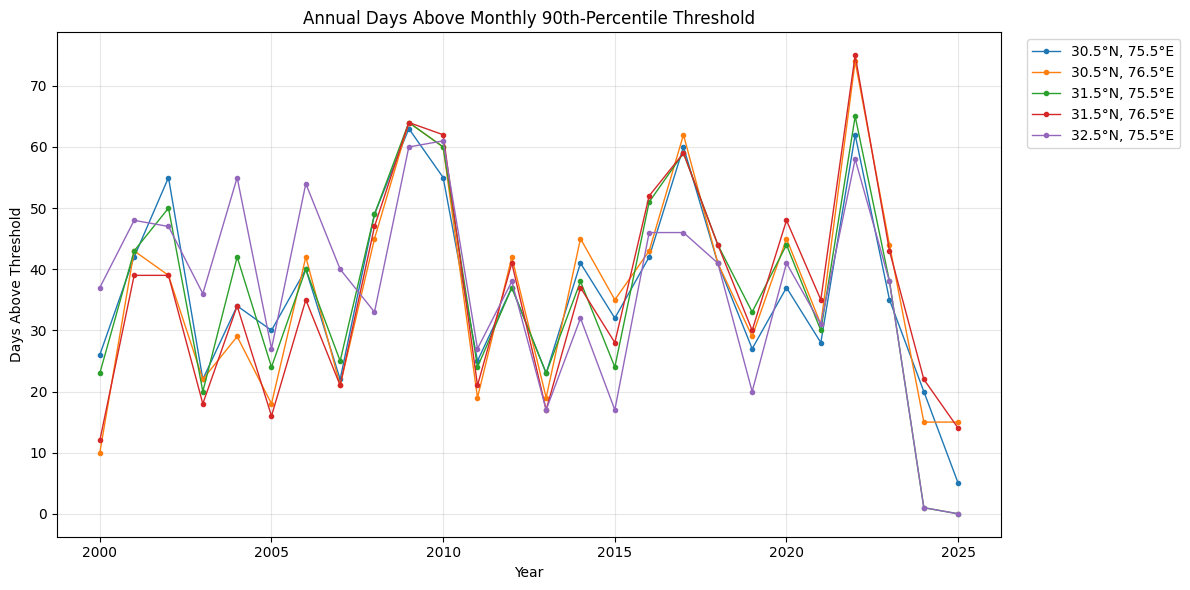

Linear trend results (exploratory only):


,latitude,longitude,trend_days_per_year,p_value,r_squared
0,30.5,75.5,-0.2656,0.4925,0.0198
1,30.5,76.5,0.3419,0.4454,0.0245
2,31.5,75.5,-0.2998,0.5123,0.0181
3,31.5,76.5,0.4749,0.2894,0.0466
4,32.5,75.5,-0.8933,0.0326,0.1765


In [29]:

from scipy.stats import linregress

# Recalculate annual extreme-day counts, excluding missing cells
valid_temperature = ds["tmax"].notnull()
daily_threshold = monthly_threshold.sel(month=ds["time"].dt.month)

extreme_day = (ds["tmax"] > daily_threshold).where(valid_temperature)

annual_extreme_days = extreme_day.groupby("time.year").sum(
    dim="time", skipna=True
)

has_data = valid_temperature.any(dim="time")
annual_extreme_days = annual_extreme_days.where(has_data)

# Create a tidy table
results = (
    annual_extreme_days
    .to_dataframe(name="extreme_heat_days")
    .reset_index()
    .dropna(subset=["extreme_heat_days"])
)

# Calculate a simple linear trend for each valid grid cell
trend_results = []

for (lat, lon), group in results.groupby(["lat", "lon"]):
    group = group.sort_values("year")
    trend = linregress(group["year"], group["extreme_heat_days"])

    trend_results.append({
        "latitude": lat,
        "longitude": lon,
        "trend_days_per_year": trend.slope,
        "p_value": trend.pvalue,
        "r_squared": trend.rvalue ** 2
    })

trend_table = pd.DataFrame(trend_results)

# Plot annual extreme-day counts
plt.figure(figsize=(12, 6))

for (lat, lon), group in results.groupby(["lat", "lon"]):
    plt.plot(
        group["year"],
        group["extreme_heat_days"],
        marker="o",
        markersize=3,
        linewidth=1,
        label=f"{lat}°N, {lon}°E"
    )

plt.title("Annual Days Above Monthly 90th-Percentile Threshold")
plt.xlabel("Year")
plt.ylabel("Days Above Threshold")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Linear trend results (exploratory only):")
display(trend_table.round(4))

results.to_csv("annual_extreme_heat_days.csv", index=False)
trend_table.to_csv("exploratory_trend_results.csv", index=False)
